In [1]:
# Importar librerías
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path

# Configurar matplotlib para que los gráficos se vean grandes y claros
plt.rcParams['figure.figsize'] = (16, 9)

### Cargar y filtrar el Ground Truth

In [2]:
# Definir rutas relativas
BASE_DIR = Path('..')
DATA_DIR = BASE_DIR / 'data' / 'MOT17' / 'train'
SEQ_NAME = 'MOT17-04-FRCNN' # Elegir una de las secuencias (se puede cambiar para explorar otras)

seq_dir = DATA_DIR / SEQ_NAME
img_dir = seq_dir / 'img1'
gt_path = seq_dir / 'gt' / 'gt.txt'

# Definir las columnas según el estándar de MOT17
mot_columns = ['frame', 'id', 'bb_left', 'bb_top', 'bb_width', 'bb_height', 'conf', 'class', 'visibility']

# Leer el CSV con Pandas
df_gt = pd.read_csv(gt_path, names=mot_columns)

# Filtrar para obtener solamente el Frame 1 y la clase Peatones (clase 1)
frame_idx = 1
df_frame = df_gt[(df_gt['frame'] == frame_idx) & (df_gt['class'] == 1)]

# Visualizar la información del frame
print(f"Secuencia: {SEQ_NAME}")
print(f"Total de peatones en el frame {frame_idx}: {len(df_frame)}")
display(df_frame.head())

Secuencia: MOT17-04-FRCNN
Total de peatones en el frame 1: 42


,frame,id,bb_left,bb_top,bb_width,bb_height,conf,class,visibility
0,1,1,1363,569,103,241,1,1,0.86014
1050,1,2,371,410,80,239,1,1,1.00000
1730,1,3,103,549,83,251,1,1,1.00000
2780,1,4,1734,457,76,213,1,1,0.98386
3830,1,5,1098,980,78,208,1,1,0.48325


### Visualizar la imagen con las Bounding Boxes

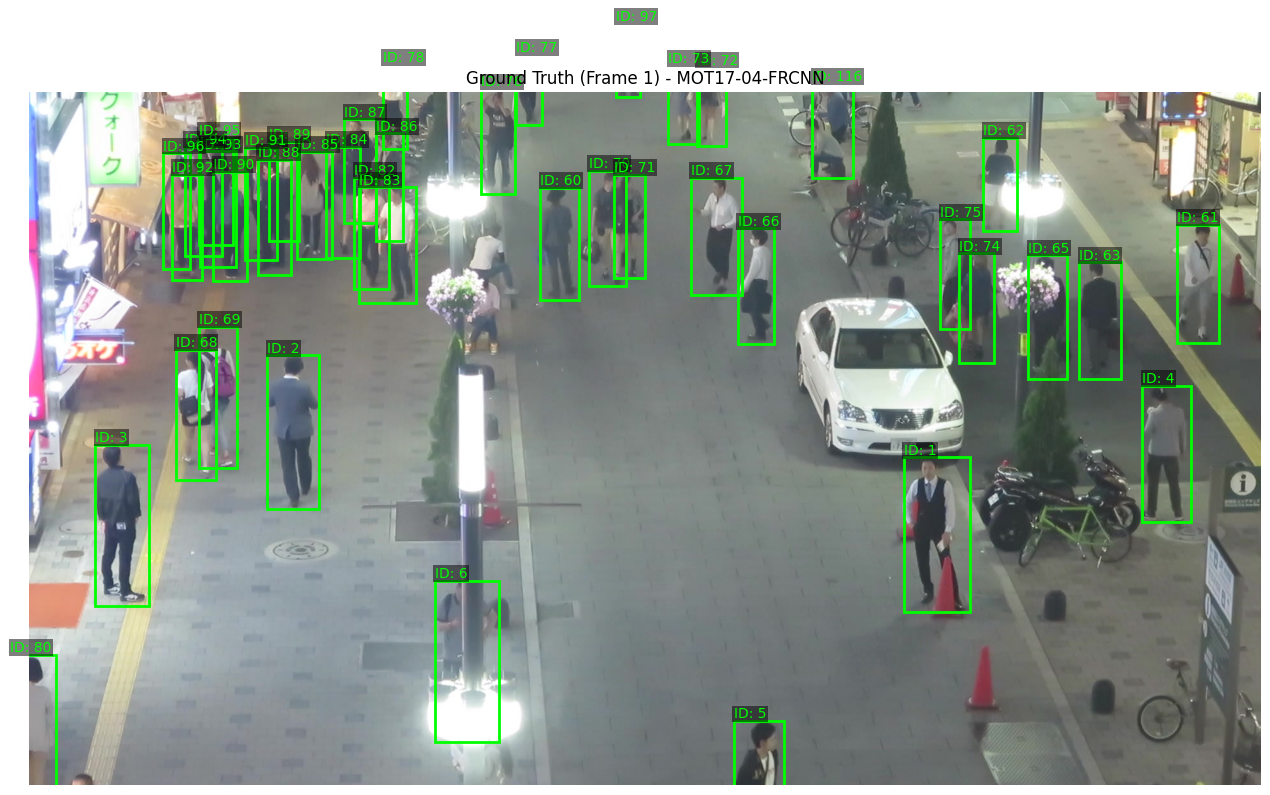

In [ ]:
# Construir la ruta de la imagen
img_name = f"{frame_idx:06d}.jpg"
img_path = img_dir / img_name

# Cargar la imagen con OpenCV (y convertir a RGB para Matplotlib)
img = cv2.imread(str(img_path))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Crear el gráfico
fig, ax = plt.subplots()
ax.imshow(img)
ax.axis('off')

# Iterar sobre las filas del dataframe filtrado y dibujar las cajas
for index, row in df_frame.iterrows():
    # Extraer coordenadas bounding box + ID del objeto
    x = row['bb_left']
    y = row['bb_top']
    w = row['bb_width']
    h = row['bb_height']
    obj_id = int(row['id'])
    
    # Crear un rectángulo en Matplotlib
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    
    # Añadir el ID del objeto encima de la caja
    ax.text(x, y - 5, f'ID: {obj_id}', color='lime', fontsize=10, 
            bbox=dict(facecolor='black', alpha=0.5, edgecolor='none', pad=1))

plt.title(f"Ground Truth (Frame {frame_idx}) - {SEQ_NAME}")
plt.show()